# Plots

About twenty matplotlib charts of different shapes, plus whatever seaborn / plotly / altair / bokeh write
(vendor MIME types such as `application/vnd.plotly.v1+json`, `application/vnd.vegalite.v5+json`,
`application/vnd.bokehjs_exec.v0+json` come with `text/html` or `text/plain` fallbacks).

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
rng = np.random.default_rng(3)
plt.rcParams.update({"figure.figsize": (6.4, 3.8), "axes.grid": True, "grid.alpha": .25})
print("matplotlib", mpl.__version__, "| backend", mpl.get_backend())

matplotlib 3.10.9 | backend inline


## matplotlib

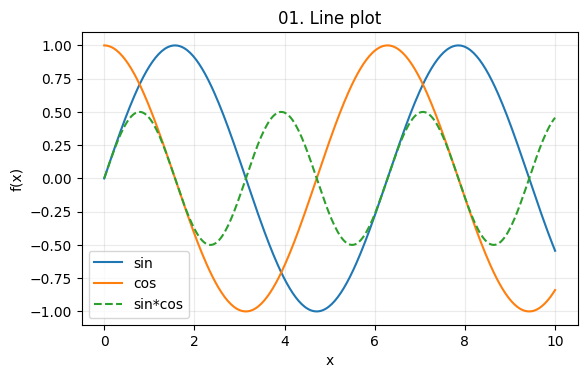

In [2]:
x = np.linspace(0, 10, 300)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x), label="sin"); ax.plot(x, np.cos(x), label="cos"); ax.plot(x, np.sin(x) * np.cos(x), "--", label="sin*cos")
ax.set(title="01. Line plot", xlabel="x", ylabel="f(x)"); ax.legend()
plt.show()

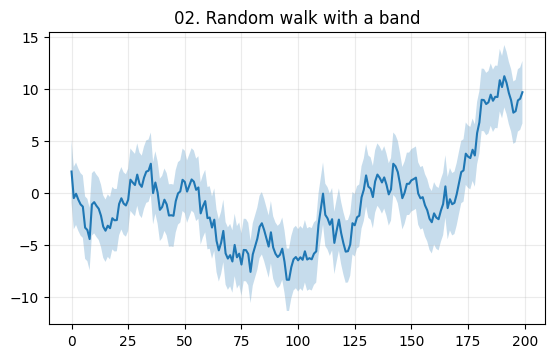

In [3]:
t = np.arange(200); y = np.cumsum(rng.normal(0, 1, 200))
fig, ax = plt.subplots()
ax.plot(t, y, color="C0"); ax.fill_between(t, y - 3, y + 3, alpha=.25)
ax.set_title("02. Random walk with a band")
plt.show()

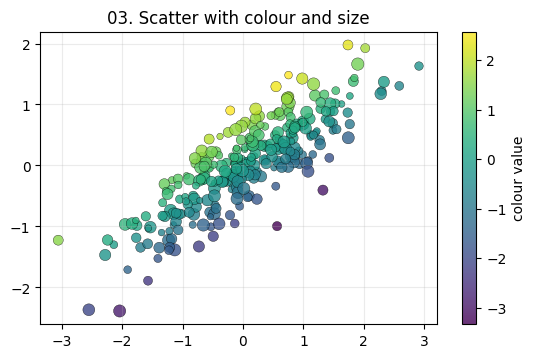

In [4]:
n = 300
a, b = rng.normal(size=n), rng.normal(size=n)
fig, ax = plt.subplots()
sc = ax.scatter(a, a * .6 + b * .4, c=b, s=20 + 60 * rng.random(n), cmap="viridis", alpha=.8, edgecolor="k", linewidth=.3)
fig.colorbar(sc, label="colour value"); ax.set_title("03. Scatter with colour and size")
plt.show()

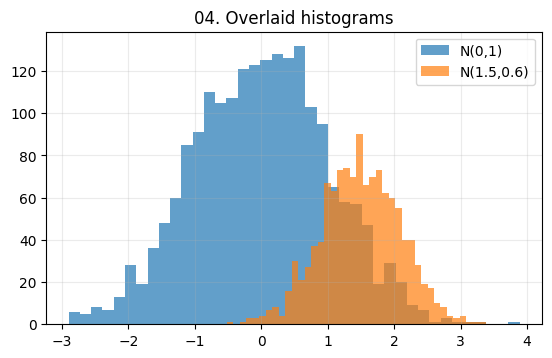

In [5]:
fig, ax = plt.subplots()
ax.hist(rng.normal(0, 1, 2000), bins=40, alpha=.7, label="N(0,1)")
ax.hist(rng.normal(1.5, .6, 1200), bins=40, alpha=.7, label="N(1.5,0.6)")
ax.legend(); ax.set_title("04. Overlaid histograms")
plt.show()

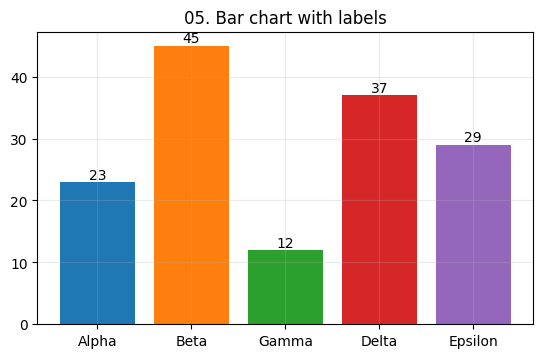

In [6]:
cats = ["Alpha", "Beta", "Gamma", "Delta", "Epsilon"]; vals = [23, 45, 12, 37, 29]
fig, ax = plt.subplots()
bars = ax.bar(cats, vals, color=plt.cm.tab10.colors[:5])
ax.bar_label(bars); ax.set_title("05. Bar chart with labels")
plt.show()

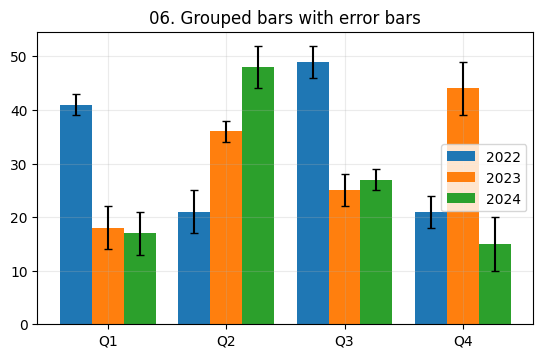

In [7]:
w = .27; xs = np.arange(4)
fig, ax = plt.subplots()
for i, name in enumerate(["2022", "2023", "2024"]):
    ax.bar(xs + (i - 1) * w, rng.integers(10, 50, 4), w, yerr=rng.integers(1, 6, 4), capsize=3, label=name)
ax.set_xticks(xs, ["Q1", "Q2", "Q3", "Q4"]); ax.legend(); ax.set_title("06. Grouped bars with error bars")
plt.show()

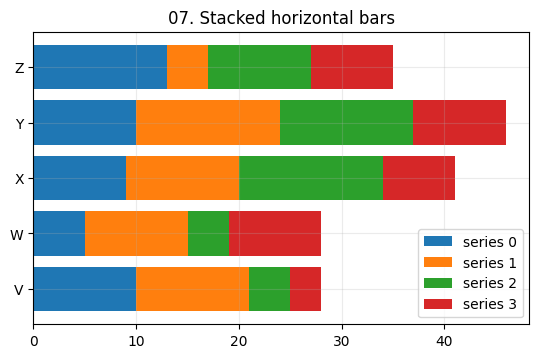

In [8]:
fig, ax = plt.subplots()
left = np.zeros(5)
for k in range(4):
    v = rng.integers(3, 15, 5); ax.barh(list("VWXYZ"), v, left=left, label=f"series {k}"); left += v
ax.legend(); ax.set_title("07. Stacked horizontal bars")
plt.show()

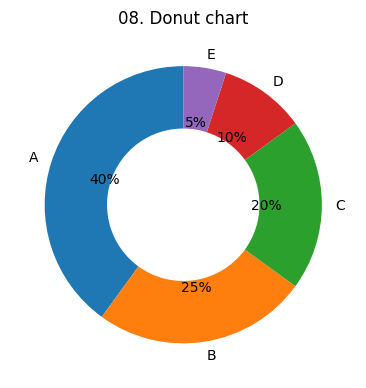

In [9]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie([40, 25, 20, 10, 5], labels=["A", "B", "C", "D", "E"], autopct="%1.0f%%", wedgeprops=dict(width=.45), startangle=90)
ax.set_title("08. Donut chart")
plt.show()

/tmp/ipykernel_81370/785351473.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  a1.boxplot(data, labels=list("ABCD")); a1.set_title("09a. Box plot")


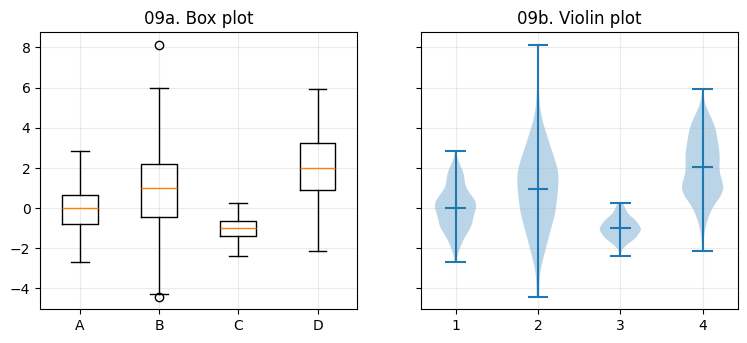

In [10]:
data = [rng.normal(m, s, 200) for m, s in [(0, 1), (1, 2), (-1, .5), (2, 1.5)]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
a1.boxplot(data, labels=list("ABCD")); a1.set_title("09a. Box plot")
a2.violinplot(data, showmeans=True); a2.set_title("09b. Violin plot")
plt.show()

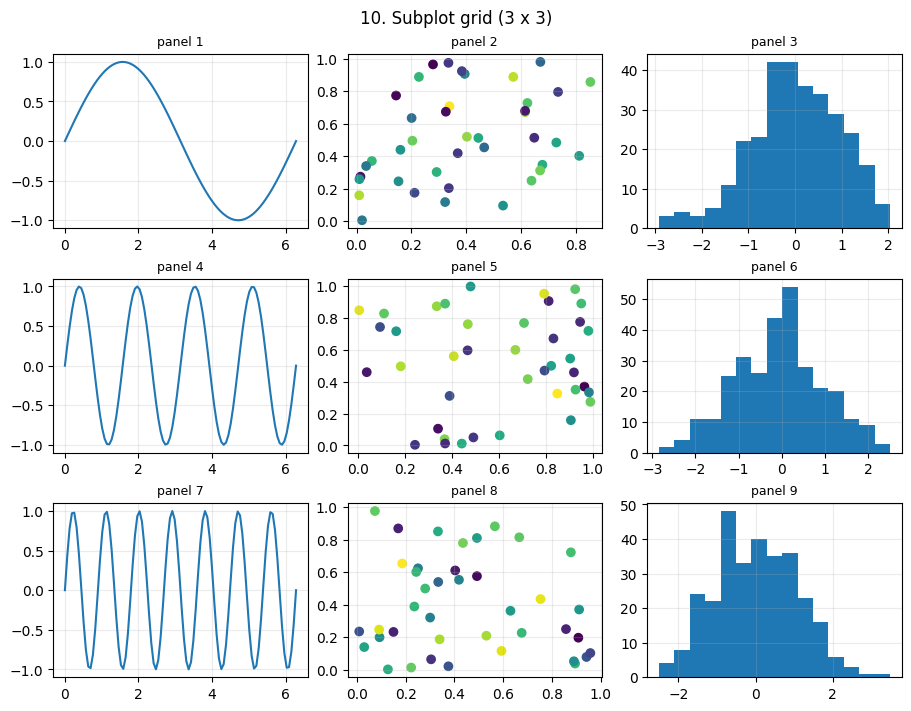

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(9, 7), constrained_layout=True)
xx = np.linspace(0, 2 * np.pi, 100)
for i, ax in enumerate(axes.flat):
    if i % 3 == 0:   ax.plot(xx, np.sin((i + 1) * xx))
    elif i % 3 == 1: ax.scatter(rng.random(40), rng.random(40), c=rng.random(40))
    else:            ax.hist(rng.normal(size=300), bins=15)
    ax.set_title(f"panel {i + 1}", fontsize=9)
fig.suptitle("10. Subplot grid (3 x 3)")
plt.show()

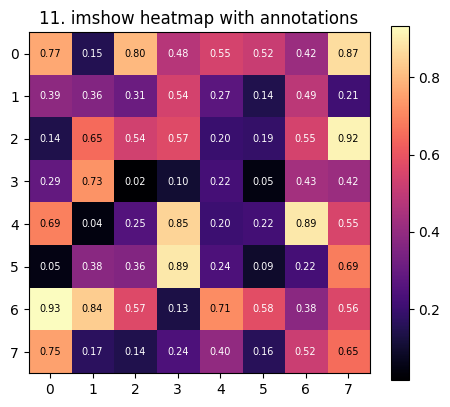

In [12]:
m = rng.random((8, 8)); 
fig, ax = plt.subplots(figsize=(5.5, 4.6))
im = ax.imshow(m, cmap="magma"); fig.colorbar(im)
for (i, j), v in np.ndenumerate(m):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="w" if v < .6 else "k", fontsize=7)
ax.set_title("11. imshow heatmap with annotations"); ax.grid(False)
plt.show()

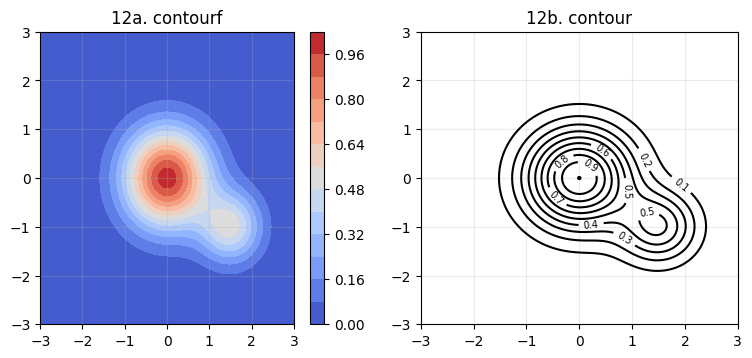

In [13]:
X, Y = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
Z = np.exp(-(X ** 2 + Y ** 2)) + .5 * np.exp(-((X - 1.5) ** 2 + (Y + 1) ** 2) * 2)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8))
cf = a1.contourf(X, Y, Z, levels=15, cmap="coolwarm"); fig.colorbar(cf, ax=a1); a1.set_title("12a. contourf")
cs = a2.contour(X, Y, Z, levels=10, colors="k"); a2.clabel(cs, fontsize=7); a2.set_title("12b. contour")
plt.show()

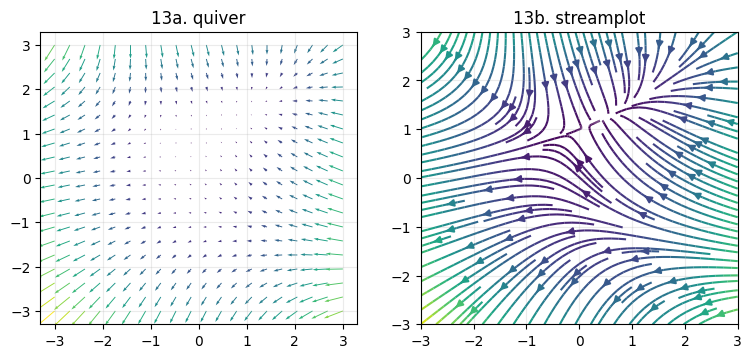

In [14]:
Y, X = np.mgrid[-3:3:20j, -3:3:20j]; U, V = -1 - X ** 2 + Y, 1 + X - Y ** 2
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8))
a1.quiver(X, Y, U, V, np.hypot(U, V)); a1.set_title("13a. quiver")
a2.streamplot(X, Y, U, V, color=np.hypot(U, V), density=1.4); a2.set_title("13b. streamplot")
plt.show()

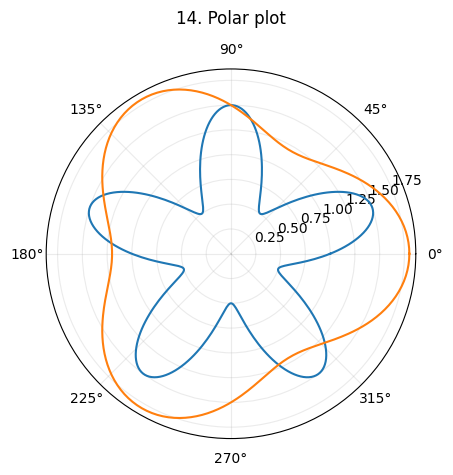

In [15]:
theta = np.linspace(0, 2 * np.pi, 400)
fig = plt.figure(figsize=(4.8, 4.8)); ax = fig.add_subplot(projection="polar")
ax.plot(theta, 1 + .5 * np.sin(5 * theta)); ax.plot(theta, 1.5 + .3 * np.cos(3 * theta))
ax.set_title("14. Polar plot", pad=14)
plt.show()

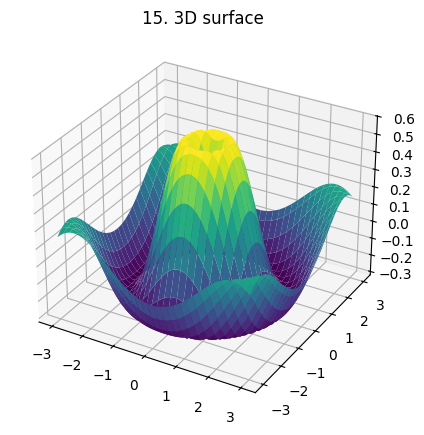

In [16]:
from matplotlib import cm
X, Y = np.meshgrid(np.linspace(-3, 3, 60), np.linspace(-3, 3, 60)); Z = np.sin(np.hypot(X, Y) * 2) / (1 + np.hypot(X, Y))
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, Z, cmap=cm.viridis, linewidth=0, antialiased=True); ax.set_title("15. 3D surface")
plt.show()

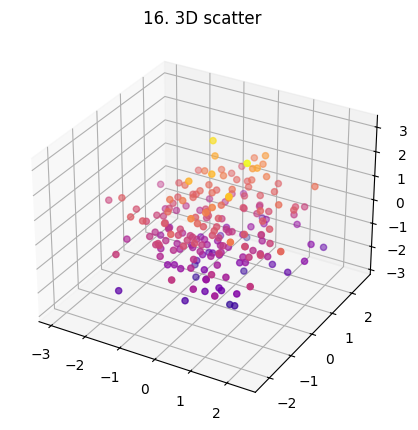

In [17]:
fig = plt.figure(figsize=(6, 5)); ax = fig.add_subplot(projection="3d")
p = rng.normal(size=(200, 3)); ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap="plasma"); ax.set_title("16. 3D scatter")
plt.show()

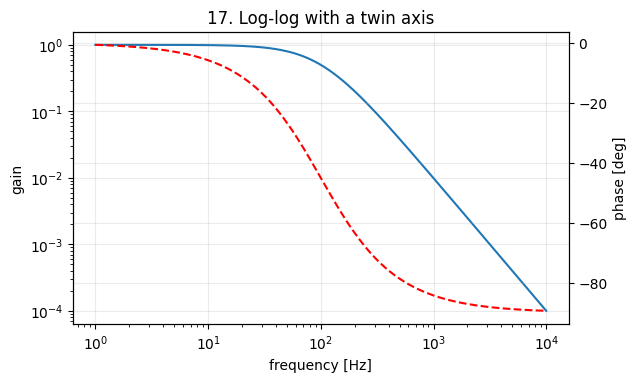

In [18]:
f = np.logspace(0, 4, 200)
fig, ax = plt.subplots()
ax.loglog(f, 1 / (1 + (f / 100) ** 2), label="low-pass"); ax.set_xlabel("frequency [Hz]"); ax.set_ylabel("gain")
ax2 = ax.twinx(); ax2.semilogx(f, -np.degrees(np.arctan(f / 100)), "r--", label="phase"); ax2.set_ylabel("phase [deg]")
ax.set_title("17. Log-log with a twin axis")
plt.show()

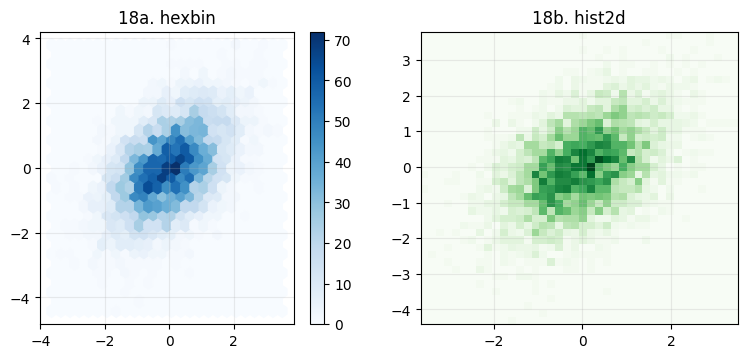

In [19]:
px, py = rng.normal(size=5000), rng.normal(size=5000)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8))
hb = a1.hexbin(px, px * .5 + py, gridsize=25, cmap="Blues"); fig.colorbar(hb, ax=a1); a1.set_title("18a. hexbin")
_ = a2.hist2d(px, px * .5 + py, bins=40, cmap="Greens"); a2.set_title("18b. hist2d")
plt.show()

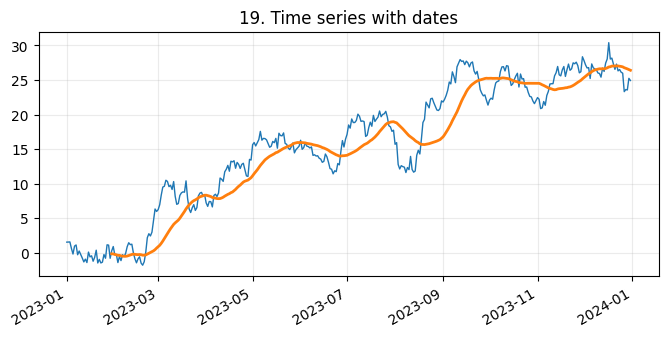

In [20]:
dates = pd.date_range("2023-01-01", periods=365)
s = pd.Series(np.cumsum(rng.normal(0, 1, 365)), index=dates)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(s.index, s.values, lw=1); ax.plot(s.index, s.rolling(30).mean(), lw=2)
fig.autofmt_xdate(); ax.set_title("19. Time series with dates")
plt.show()

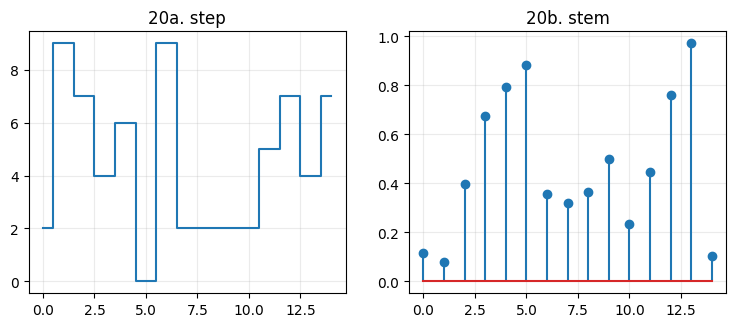

In [21]:
k = np.arange(15)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
a1.step(k, rng.integers(0, 10, 15), where="mid"); a1.set_title("20a. step")
a2.stem(k, rng.random(15)); a2.set_title("20b. stem")
plt.show()

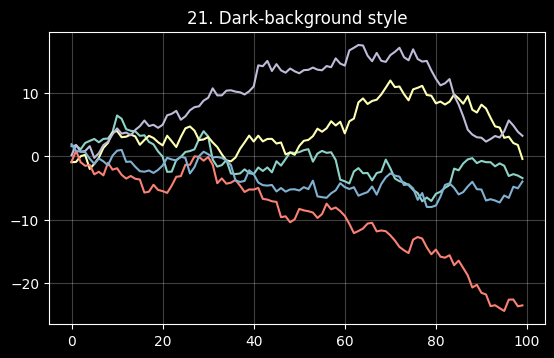

In [22]:
with plt.style.context("dark_background"):
    fig, ax = plt.subplots()
    for i in range(5): ax.plot(np.cumsum(rng.normal(size=100)), lw=1.5)
    ax.set_title("21. Dark-background style")
    plt.show()

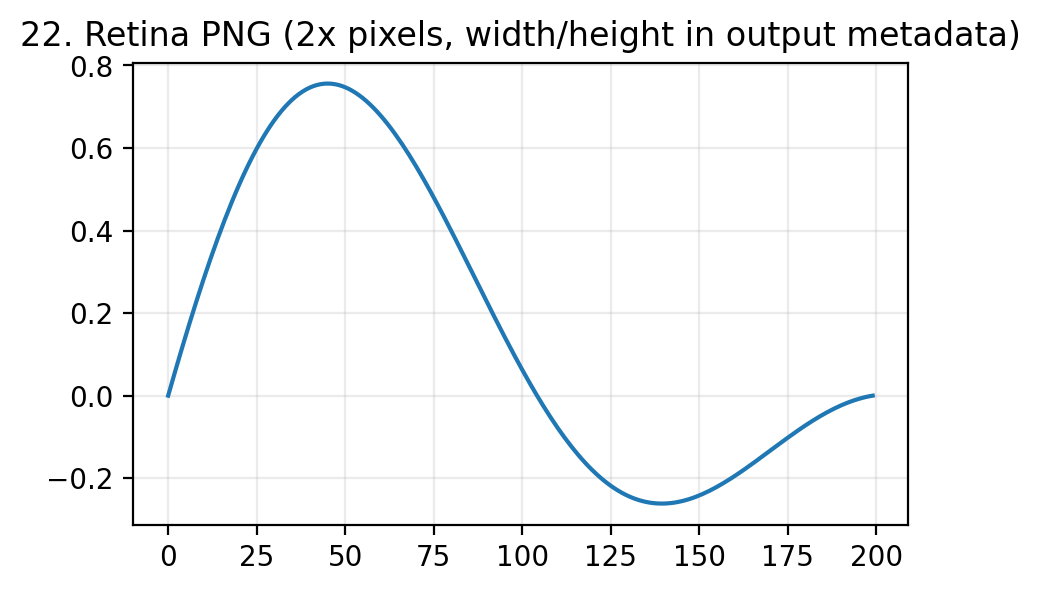

In [23]:
%config InlineBackend.figure_format = 'retina'
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.sin(np.linspace(0, 6, 200)) * np.linspace(1, 0, 200)); ax.set_title("22. Retina PNG (2x pixels, width/height in output metadata)")
plt.show()

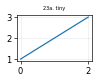

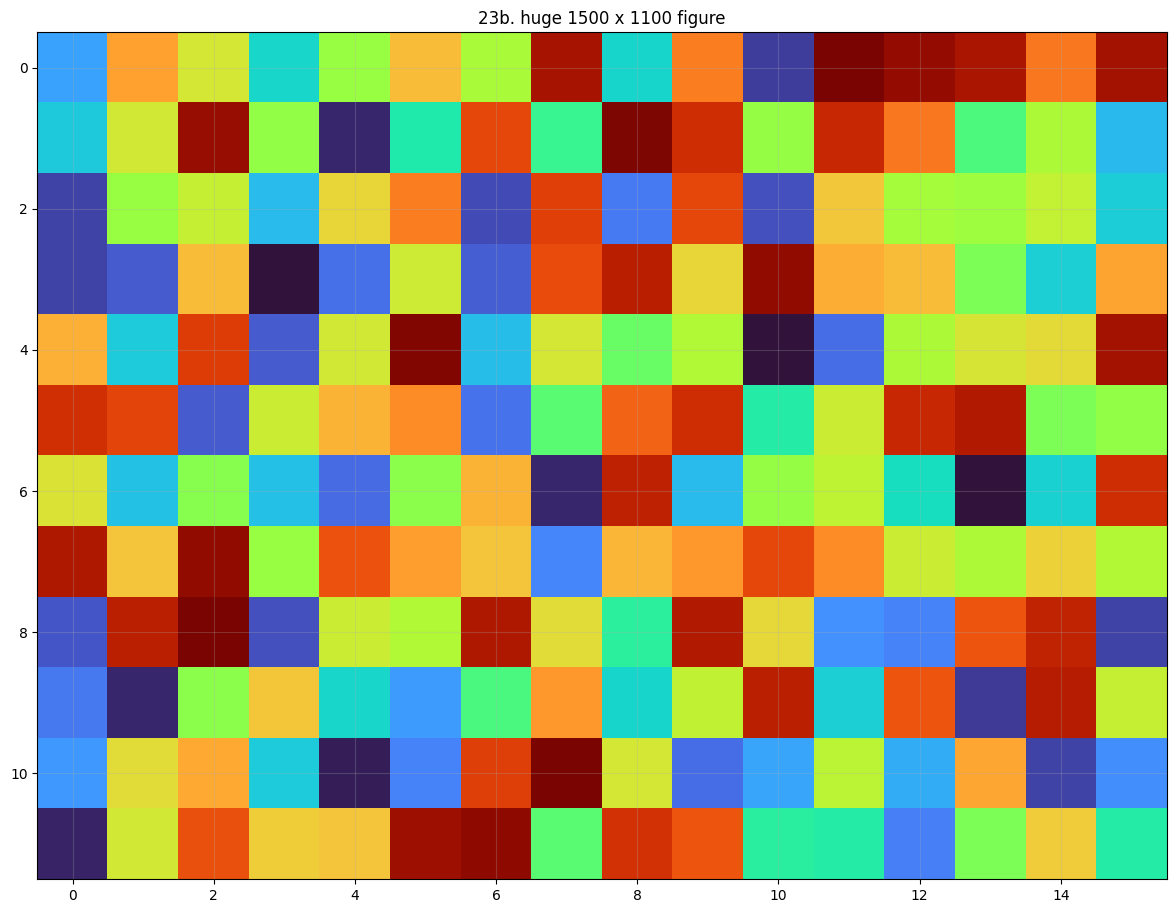

In [24]:
%config InlineBackend.figure_format = 'png'
fig, ax = plt.subplots(figsize=(1.6, 1.0), dpi=60); ax.plot([1, 2, 3]); ax.set_title("23a. tiny", fontsize=6)
plt.show()
fig, ax = plt.subplots(figsize=(15, 11), dpi=100)
ax.imshow(rng.random((12, 16)), cmap="turbo", interpolation="nearest"); ax.set_title("23b. huge 1500 x 1100 figure")
plt.show()

/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 35486 (\N{CJK UNIFIED IDEOGRAPH-8A9E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 12479 (\N{KATAKANA LETTER TA}) missing from font(s) DejaVu Sans.
  fig.ca

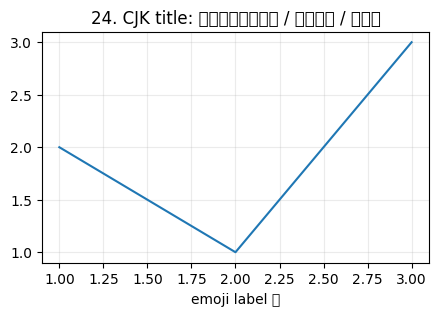

In [25]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([1, 2, 3], [2, 1, 3]); ax.set_title("24. CJK title: 日本語のタイトル / 中文标题 / 한국어")
ax.set_xlabel("emoji label 🚀")
plt.show()

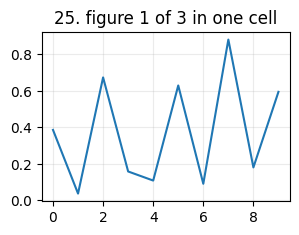

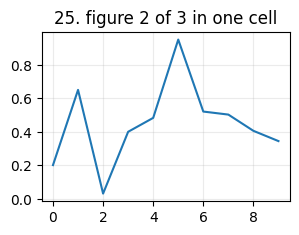

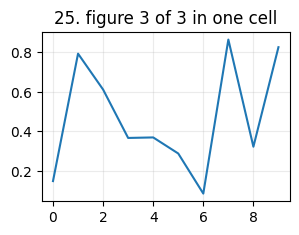

In [26]:
for i in range(3):
    fig, ax = plt.subplots(figsize=(3.2, 2.2)); ax.plot(rng.random(10)); ax.set_title(f"25. figure {i + 1} of 3 in one cell")
    plt.show()

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

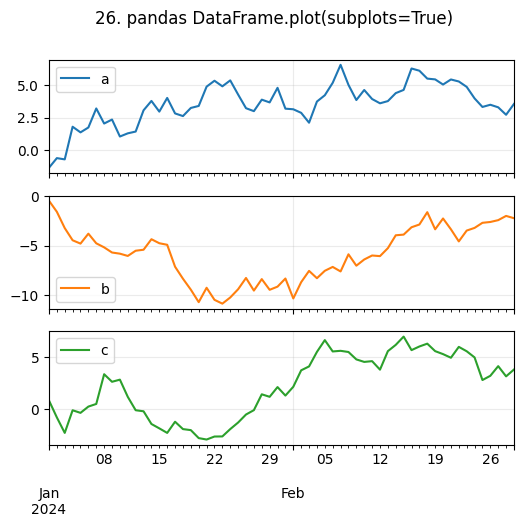

In [27]:
ts = pd.DataFrame({"a": np.cumsum(rng.normal(size=60)), "b": np.cumsum(rng.normal(size=60)), "c": np.cumsum(rng.normal(size=60))},
                  index=pd.date_range("2024-01-01", periods=60))
ts.plot(subplots=True, figsize=(6, 5), title="26. pandas DataFrame.plot(subplots=True)")    # bare: Axes array repr + figure

In [28]:
from matplotlib import animation
from IPython.display import HTML
fig, ax = plt.subplots(figsize=(3.2, 2))
xs = np.linspace(0, 2 * np.pi, 100); (line,) = ax.plot(xs, np.sin(xs)); ax.set_ylim(-1.2, 1.2); ax.set_title("27. FuncAnimation")
def update(i):
    line.set_ydata(np.sin(xs + i / 2)); return (line,)
ani = animation.FuncAnimation(fig, update, frames=12, interval=80, blit=True)
plt.close(fig)
HTML(ani.to_jshtml())      # text/html: a JS player with base64 PNG frames

## seaborn

<Axes: xlabel='total_bill', ylabel='tip'>

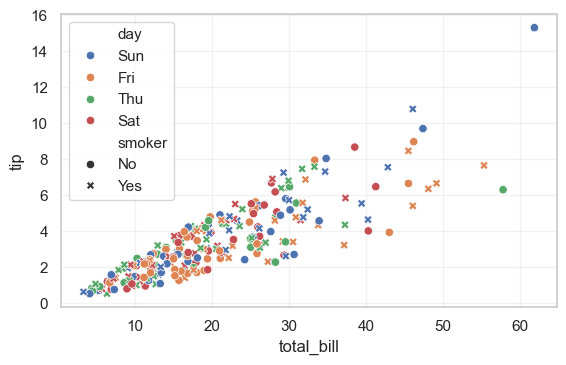

In [29]:
import seaborn as sns
sns.set_theme(style="whitegrid")
n = 240
tips = pd.DataFrame({"total_bill": rng.gamma(4, 5, n).round(2), "day": rng.choice(["Thu", "Fri", "Sat", "Sun"], n),
                     "smoker": rng.choice(["Yes", "No"], n), "size": rng.integers(1, 6, n)})
tips["tip"] = (tips.total_bill * rng.uniform(.08, .25, n)).round(2)
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="day", style="smoker")     # bare: Axes repr + figure

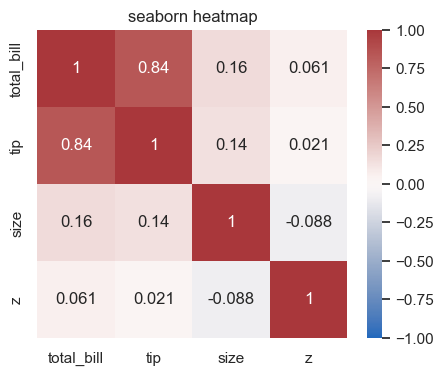

In [30]:
corr = tips[["total_bill", "tip", "size"]].assign(z=rng.normal(size=n)).corr()
plt.figure(figsize=(5, 4)); sns.heatmap(corr, annot=True, cmap="vlag", vmin=-1, vmax=1); plt.title("seaborn heatmap")
plt.show()

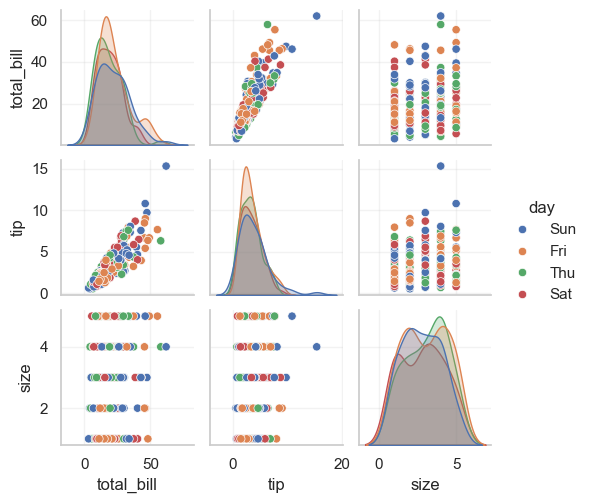

In [31]:
sns.pairplot(tips[["total_bill", "tip", "size", "day"]], hue="day", height=1.7)       # PairGrid repr + large figure

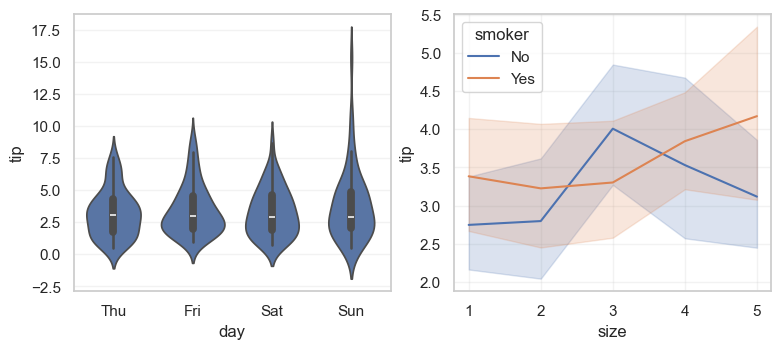

In [32]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.6))
sns.violinplot(data=tips, x="day", y="tip", ax=a1, order=["Thu", "Fri", "Sat", "Sun"]); sns.lineplot(data=tips, x="size", y="tip", hue="smoker", ax=a2)
plt.show()

## plotly

In [33]:
import plotly.express as px, plotly.io as pio
print("default renderer:", pio.renderers.default)
fig = px.scatter(tips, x="total_bill", y="tip", color="day", size="size", title="plotly express scatter")
fig.show()

default renderer: plotly_mimetype+notebook


In [34]:
import plotly.graph_objects as go
fig = go.Figure(go.Bar(x=["A", "B", "C", "D"], y=[4, 7, 3, 9], marker_color=["#636efa", "#ef553b", "#00cc96", "#ab63fa"]))
fig.update_layout(title="plotly graph_objects bar")
fig.show()

In [35]:
X, Y = np.meshgrid(np.linspace(-3, 3, 40), np.linspace(-3, 3, 40))
go.Figure(go.Surface(z=np.sin(np.hypot(X, Y) * 2), x=X, y=Y), layout=dict(title="plotly 3D surface (bare figure -> _repr_mimebundle_)", height=450))

## altair

In [36]:
import altair as alt
cars = pd.DataFrame({"hp": rng.integers(60, 250, 120), "mpg": rng.normal(25, 6, 120).round(1), "origin": rng.choice(["USA", "Europe", "Japan"], 120)})
alt.Chart(cars).mark_point().encode(x="hp", y="mpg", color="origin", tooltip=["hp", "mpg", "origin"]).properties(title="altair scatter", width=360, height=220)

/opt/anaconda3/lib/python3.13/site-packages/altair/utils/core.py:395: FutureWarning:

the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.



alt.Chart(...)

In [37]:
base = alt.Chart(cars).encode(x=alt.X("origin:N"), y=alt.Y("mean(mpg):Q"))
(base.mark_bar(opacity=.6) + base.mark_point(color="red", size=100)).properties(title="altair layered chart", width=300)

/opt/anaconda3/lib/python3.13/site-packages/altair/utils/core.py:395: FutureWarning:

the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.



alt.LayerChart(...)

In [38]:
alt.Chart(cars).mark_bar().encode(x=alt.X("mpg:Q", bin=alt.Bin(maxbins=20)), y="count()", color="origin").facet("origin:N", columns=3).properties(title="altair faceted histogram")

/opt/anaconda3/lib/python3.13/site-packages/altair/utils/core.py:395: FutureWarning:

the convert_dtype parameter is deprecated and will be removed in a future version.  Do ``ser.astype(object).apply()`` instead if you want ``convert_dtype=False``.



alt.FacetChart(...)

## bokeh

In [39]:
from bokeh.plotting import figure, show
from bokeh.io import output_notebook
output_notebook()
p = figure(width=500, height=260, title="bokeh line + scatter")
xs = np.arange(30); p.line(xs, np.cumsum(rng.normal(size=30)), line_width=2); p.scatter(xs, np.cumsum(rng.normal(size=30)), size=8, color="firebrick")
show(p)

Loading BokehJS ...